In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor

In [2]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [3]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [5]:
#Filling missing values

imp_mean = SimpleImputer(strategy='mean')
df[['age']] = imp_mean.fit_transform(df[['age']])

imp_frq = SimpleImputer(strategy='most_frequent')
df[['embarked']] = imp_frq.fit_transform(df[['embarked']])

In [6]:
#One hot Encoding
cols = ['sex']
enc = OneHotEncoder(drop="first", sparse_output=False,handle_unknown='ignore')
encoded = enc.fit_transform(df[cols])
encoded_df = pd.DataFrame(encoded,columns=enc.get_feature_names_out(cols),index = df.index)
df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)
df.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,sex_male
0,0,3,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,1.0
1,1,1,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,0.0
2,1,3,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,0.0
3,1,1,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,0.0
4,0,3,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,1.0


In [7]:
#Label Encoding 
le = LabelEncoder()

df['class'] = le.fit_transform(df['class'])
df.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,sex_male
0,0,3,22.0,1,0,7.2500,S,2,man,True,NaN,Southampton,no,False,1.0
1,1,1,38.0,1,0,71.2833,C,0,woman,False,C,Cherbourg,yes,False,0.0
2,1,3,26.0,0,0,7.9250,S,2,woman,False,NaN,Southampton,yes,True,0.0
3,1,1,35.0,1,0,53.1000,S,0,woman,False,C,Southampton,yes,False,0.0
4,0,3,35.0,0,0,8.0500,S,2,man,True,NaN,Southampton,no,True,1.0


In [8]:
df['embarked'] = le.fit_transform(df['embarked'])
df.head()

,survived,pclass,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,sex_male
0,0,3,22.0,1,0,7.2500,2,2,man,True,NaN,Southampton,no,False,1.0
1,1,1,38.0,1,0,71.2833,0,0,woman,False,C,Cherbourg,yes,False,0.0
2,1,3,26.0,0,0,7.9250,2,2,woman,False,NaN,Southampton,yes,True,0.0
3,1,1,35.0,1,0,53.1000,2,0,woman,False,C,Southampton,yes,False,0.0
4,0,3,35.0,0,0,8.0500,2,2,man,True,NaN,Southampton,no,True,1.0


In [9]:
features = ['sex_male','age','embarked','fare','class']
target = ['survived']

X = df[features]
y = df[target]

X.head()


,sex_male,age,embarked,fare,class
0,1.0,22.0,2,7.2500,2
1,0.0,38.0,0,71.2833,0
2,0.0,26.0,2,7.9250,2
3,0.0,35.0,2,53.1000,0
4,1.0,35.0,2,8.0500,2


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

print("Accuracy : ",accuracy_score(y_test,y_pred))

Accuracy :  0.7541899441340782


# Plotting the Decision tree

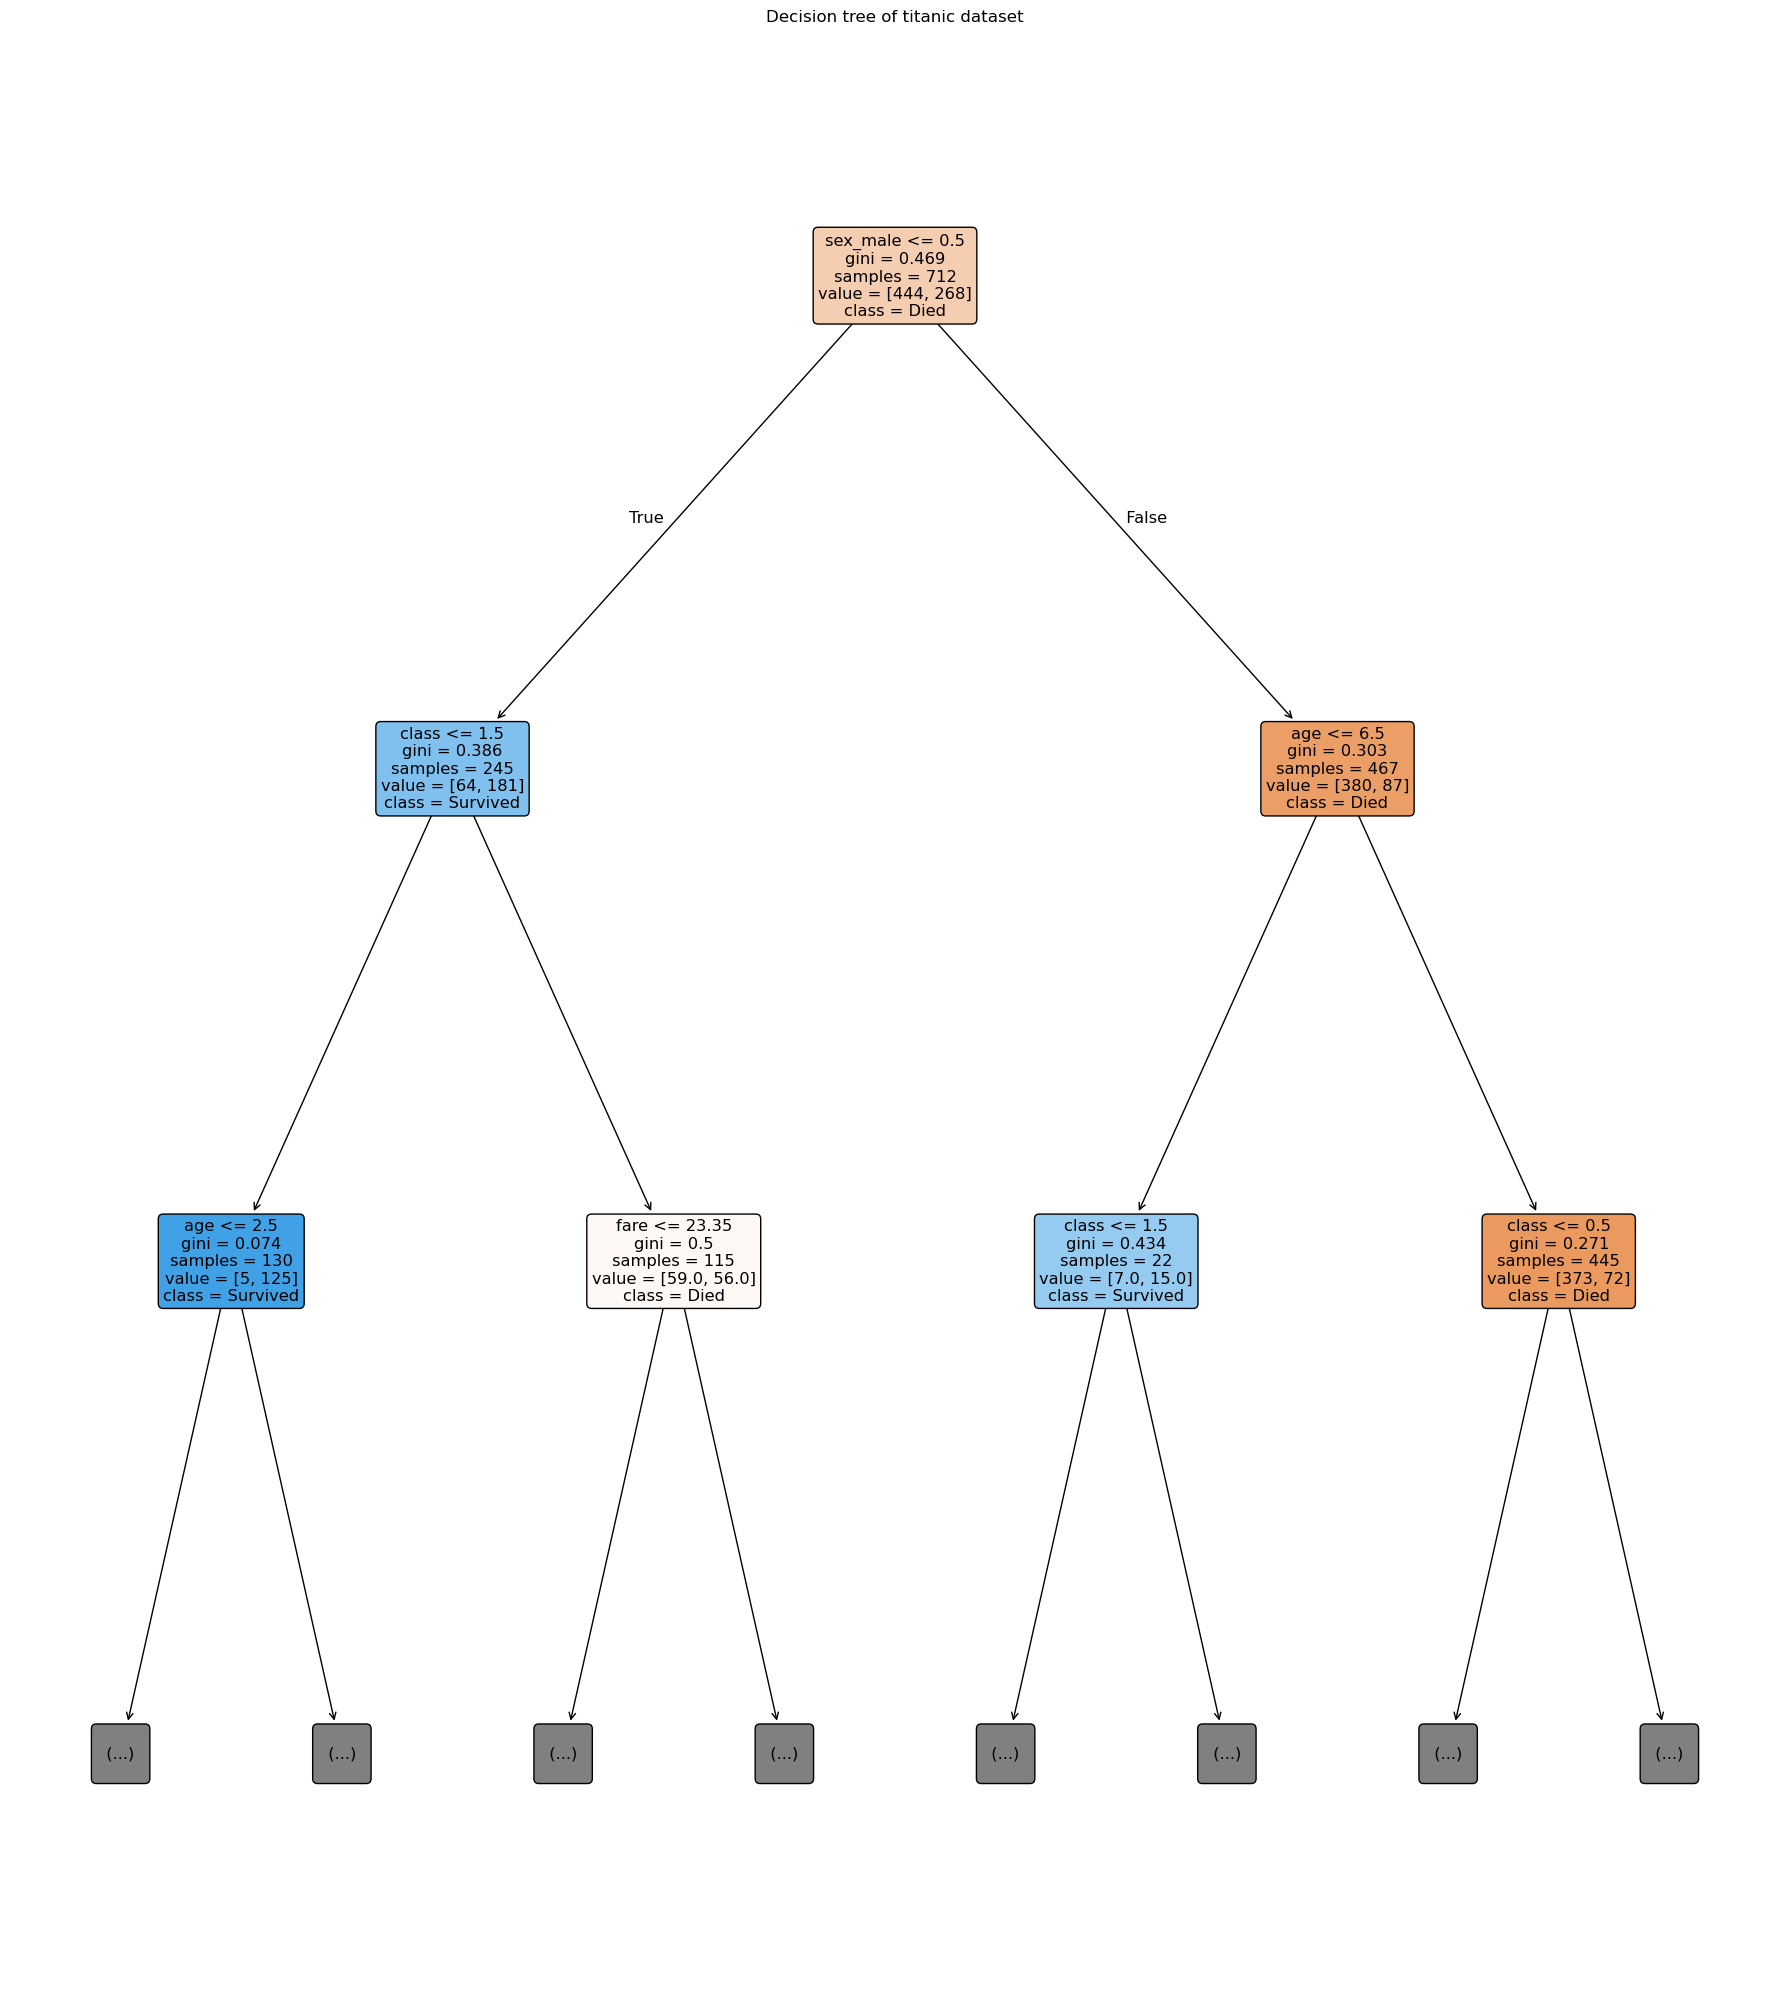

In [11]:
from  sklearn.tree import plot_tree

plt.figure(figsize=(18,20))
plot_tree(model, feature_names=X.columns ,max_depth=2, class_names=['Died','Survived'],filled=True, rounded= True)
plt.tight_layout()
plt.title("Decision tree of titanic dataset")
plt.show()

# Model training with pre-pruning

In [12]:
#Deciding the perfect max-depth parameter value
maxDepths = [2,3,4,5,6,7,8,9,10]

for depth in maxDepths:
    model = DecisionTreeClassifier(max_depth=depth)
    model.fit(X_train,y_train)

    print(f'For depth = {depth} , accuracy = {model.score(X_test,y_test)}')

For depth = 2 , accuracy = 0.7653631284916201
For depth = 3 , accuracy = 0.7988826815642458
For depth = 4 , accuracy = 0.7988826815642458
For depth = 5 , accuracy = 0.7988826815642458
For depth = 6 , accuracy = 0.8044692737430168
For depth = 7 , accuracy = 0.8044692737430168
For depth = 8 , accuracy = 0.7877094972067039
For depth = 9 , accuracy = 0.7988826815642458
For depth = 10 , accuracy = 0.7988826815642458


In [13]:
best_depth = 6

#Deciding the perfect min-sample-split parameter value
minSplits = [5, 10,15,20,25,30]

for split in minSplits:
    model = DecisionTreeClassifier(max_depth=best_depth, min_samples_split = split)
    model.fit(X_train,y_train)

    print(f'For split = {split} , accuracy = {model.score(X_test,y_test)}')

best_split  = 10

For split = 5 , accuracy = 0.7988826815642458
For split = 10 , accuracy = 0.8100558659217877
For split = 15 , accuracy = 0.8044692737430168
For split = 20 , accuracy = 0.8044692737430168
For split = 25 , accuracy = 0.7988826815642458
For split = 30 , accuracy = 0.7877094972067039


# Deciison tree post pruning -- Cost Complexity Pruning (CCP)

In [14]:
full_tree = DecisionTreeClassifier(random_state=42)

full_tree.fit(X_train,y_train)
paths = full_tree.cost_complexity_pruning_path(X_train,y_train)

ccp_alphas =paths.ccp_alphas

In [15]:
trees =[]

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    model.fit(X_train,y_train)
    trees.append((model, alpha))

best_acc =0
best_alpha =0
for model,alpha in trees:
    acc = model.score(X_test,y_test)
    if acc > best_acc : 
        best_acc = acc
        best_alpha = alpha
        

In [16]:
best_model = DecisionTreeClassifier(random_state = 42, ccp_alpha = best_alpha)
best_model.fit(X_train,y_train)
print("Best model accuracy : ", best_model.score(X_test,y_test))

Best model accuracy :  0.8435754189944135


In [17]:
model = DecisionTreeClassifier(random_state = 42, ccp_alpha = best_alpha, min_samples_split=best_split, max_depth=best_depth)
model.fit(X_train,y_train)
print("Accuracy : ",model.score(X_test,y_test))

Accuracy :  0.8100558659217877


# Decision Tree Regressor

In [18]:
from sklearn.datasets import load_diabetes


In [19]:
diabetes_df = load_diabetes(as_frame=True).frame

In [20]:
diabetes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [21]:
X = diabetes_df.drop(columns= ['target'])
y = diabetes_df['target']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
treeReg = DecisionTreeRegressor(max_depth=7,min_samples_leaf=30,min_samples_split=40)
treeReg.fit(X_train,y_train)

print("Accuracy : ",treeReg.score(X_test,y_test))

Accuracy :  0.434909548984292


In [46]:
from sklearn.metrics import r2_score, mean_squared_error

y_pred_train = treeReg.predict(X_train)
y_pred_test = treeReg.predict(X_test)

print(f"MSE train : {mean_squared_error(y_train,y_pred_train)}")
print(f"MSE test : {mean_squared_error(y_test,y_pred_test)}")
print(f"R2 Score train : {r2_score(y_train,y_pred_train)}")
print(f"R2 Score test : {r2_score(y_test,y_pred_test)}")



MSE train : 3150.8424354585054
MSE test : 2993.934961118908
R2 Score train : 0.48146213781166225
R2 Score test : 0.434909548984292
